In [69]:
from langgraph.graph import StateGraph,START,END,state
from typing import TypedDict
from langchain.messages import HumanMessage,AIMessage
from pydantic import Field
from langchain_nvidia_ai_endpoints import ChatNVIDIA
from dotenv import load_dotenv

In [70]:
load_dotenv()

True

In [71]:
model=ChatNVIDIA(model='nvidia/nemotron-3.5-super-vl-120b-a12b')

In [72]:
class Chat(TypedDict):
    messages:str=Field(...,description='Chat with the Synapse AI')

In [73]:
def chat(state:Chat)->Chat:
    response=model.invoke(state['messages'])

    return {'messages':[response.content]}

In [74]:
graph=StateGraph(Chat)

graph.add_node('chat',chat)
graph.add_edge(START,'chat')
graph.add_edge('chat',END)

workflow=graph.compile()

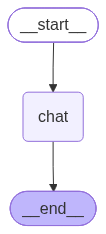

In [75]:
workflow

In [76]:
initial_state={'messages':[HumanMessage(content='What is MCP SERVER')]}

In [ ]:
final_state=workflow.invoke(initial_state)

In [90]:
final_state['messages'][-1]

'**MCP** stands for **Model Context Protocol**. An **MCP Server** is a program that connects an AI assistant (like Claude) to external data sources, tools, or systems using that protocol.\n\nThink of MCP as a **“USB-C port for AI”**: instead of every AI application building a custom integration for Google Drive, GitHub, Slack, or a local database, developers build one MCP Server that speaks the standard protocol, and any MCP-compatible AI client can plug into it.\n\n---\n\n### What an MCP Server Actually Does\n\nAn MCP Server acts as a bridge between an AI model and a specific system. It exposes three main types of capabilities:\n\n| Capability | What it is | Example |\n|------------|-----------|---------|\n| **Resources** | Data the AI can read | A file on your computer, a row in a PostgreSQL database, a Slack message |\n| **Tools** | Actions the AI can take (with your permission) | Create a GitHub issue, send an email, update a row in Salesforce |\n| **Prompts** | Pre-written templat

In [91]:
chat_history={}

In [94]:
chat_history.update({'HumanMessage':'Hi'})

In [96]:
chat_history.update({'AIMessage':'Hi how are you'})

In [97]:
chat_history

{'HumanMessage': 'Hi', 'AIMessage': 'Hi how are you'}